In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import importlib

from matplotlib import pyplot as plt

import debug.qm_env_plots as debug
import environments.classes.closed_schroedinger_env as schroedinger
import environments.qm_env as env
import environments.qm_env_wrapper as wrapper
import sac.train as sac_train
from sac.utils import evaluate

for module in [schroedinger, wrapper, debug, sac_train, evaluate, env]:
    importlib.reload(module)

In [ ]:
seed = 0

Nb = 4
Nc = Nb * 3

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": Nb * 3,
    "Nb": Nb,
    
    "dt": 0.05,
    "tau": 5.6,

    "kappa": 0.0,

    #for SAC
    "min_u": -0.3,
    "max_u": 0.3,

    "objective": "ergotropy_full",

    "reward_coeff": 1.0
}

HYPER_PARAMS = {
    "BATCH_SIZE": 256,            #batch size

    "LR": 0.001,                  #learning rate for Q and Pi loss
    "ALPHA_LR": 0.003,            #learning rate to tune the temperature parameters alpha 

    "H_START": 0.72,              #initial target entropy of the policy
    "H_END": -3.,                 #final target entropy of the policy
    "H_DECAY": 200000,            #exponential decay of the target entropy of the policy

    "C_START": [1./Nb, 0.],       #initial weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_END": [0., 1.],            #final weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_MEAN": 40000,              #timestep number where the weights are half way between start and end
    "C_WIDTH": 20000,             #width in timesteps to transition from start and end weights        

    "REPLAY_MEMORY_SIZE": 150000, #size of the replay buffer

    "POLYAK": 0.995,              #polyak coefficient

    "GAMMA": 0.993,               #RL discount factor

    "HIDDEN_SIZES": (512,256),    #size of hidden layers of the neural networks
    
    "INITIAL_RANDOM_STEPS": 5000, #number of initial uniformly random steps
    "UPDATE_AFTER": 1000,         #start minimizing loss function after initial steps
    "UPDATE_EVERY": 50,           #performs this many updates every this many steps

    "USE_CUDA": True,             #use cuda for computation

    "MIN_COV_EIGEN": 1.e-7,       #security parameter for the covariance matrix of the policy

    "PLOT_LOG" : True,            #plot realtime log data
    "LOG_EVERY": 100,             #interval at which sac params will be logged and plotted
}

In [3]:
env = schroedinger.CLosed_Schroedinger_Env(params = ENV_PARAMS)

gym_env = wrapper.GymEnvironment(env, ENV_PARAMS)

SAC Training:   0%|          | 0/150000 [00:00<?, ?step/s]

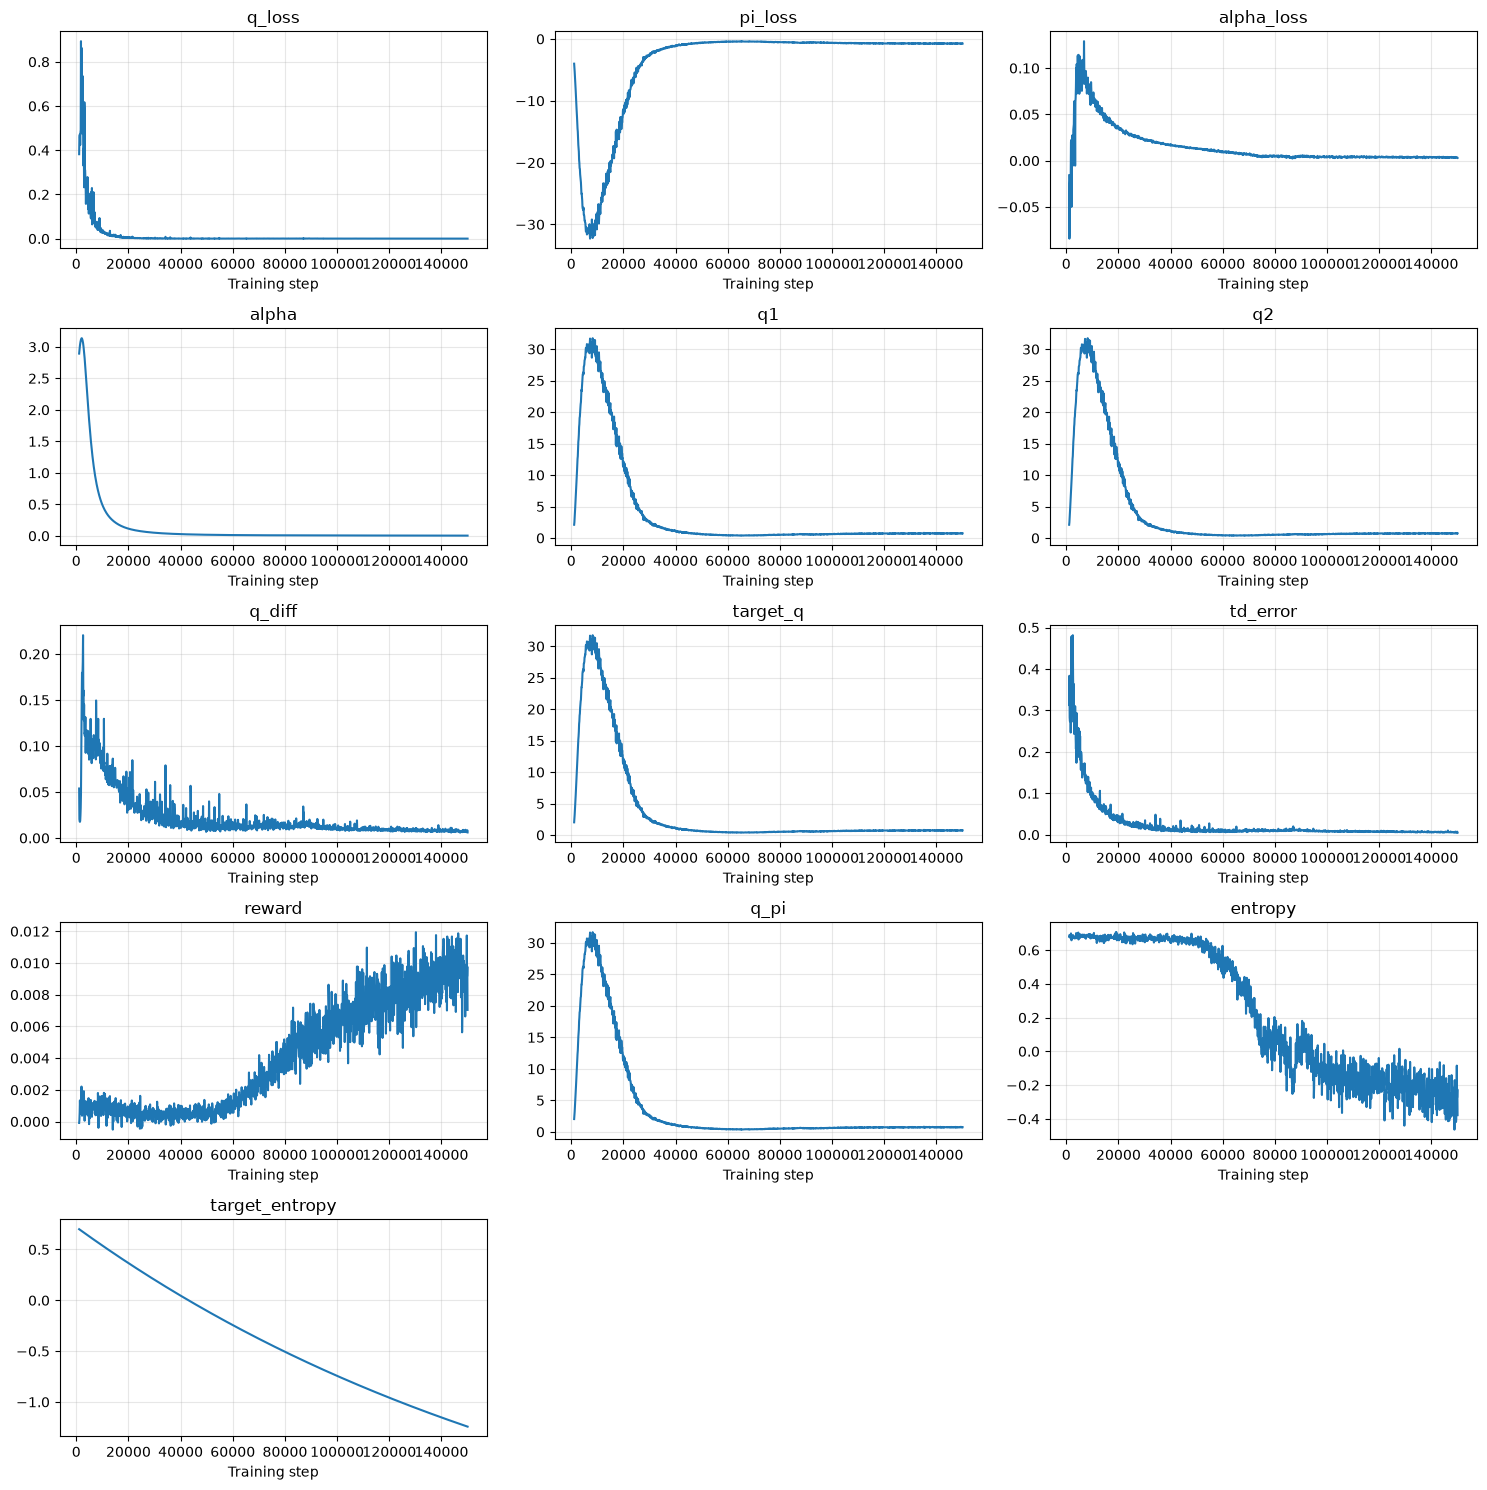

In [4]:
agent = sac_train.train(gym_env, HYPER_PARAMS, seed = seed, steps = 150000)

In [8]:
times, actions, final_info = evaluate.get_control_sequence(gym_env, agent, seed = seed)

history = env.replay(actions)

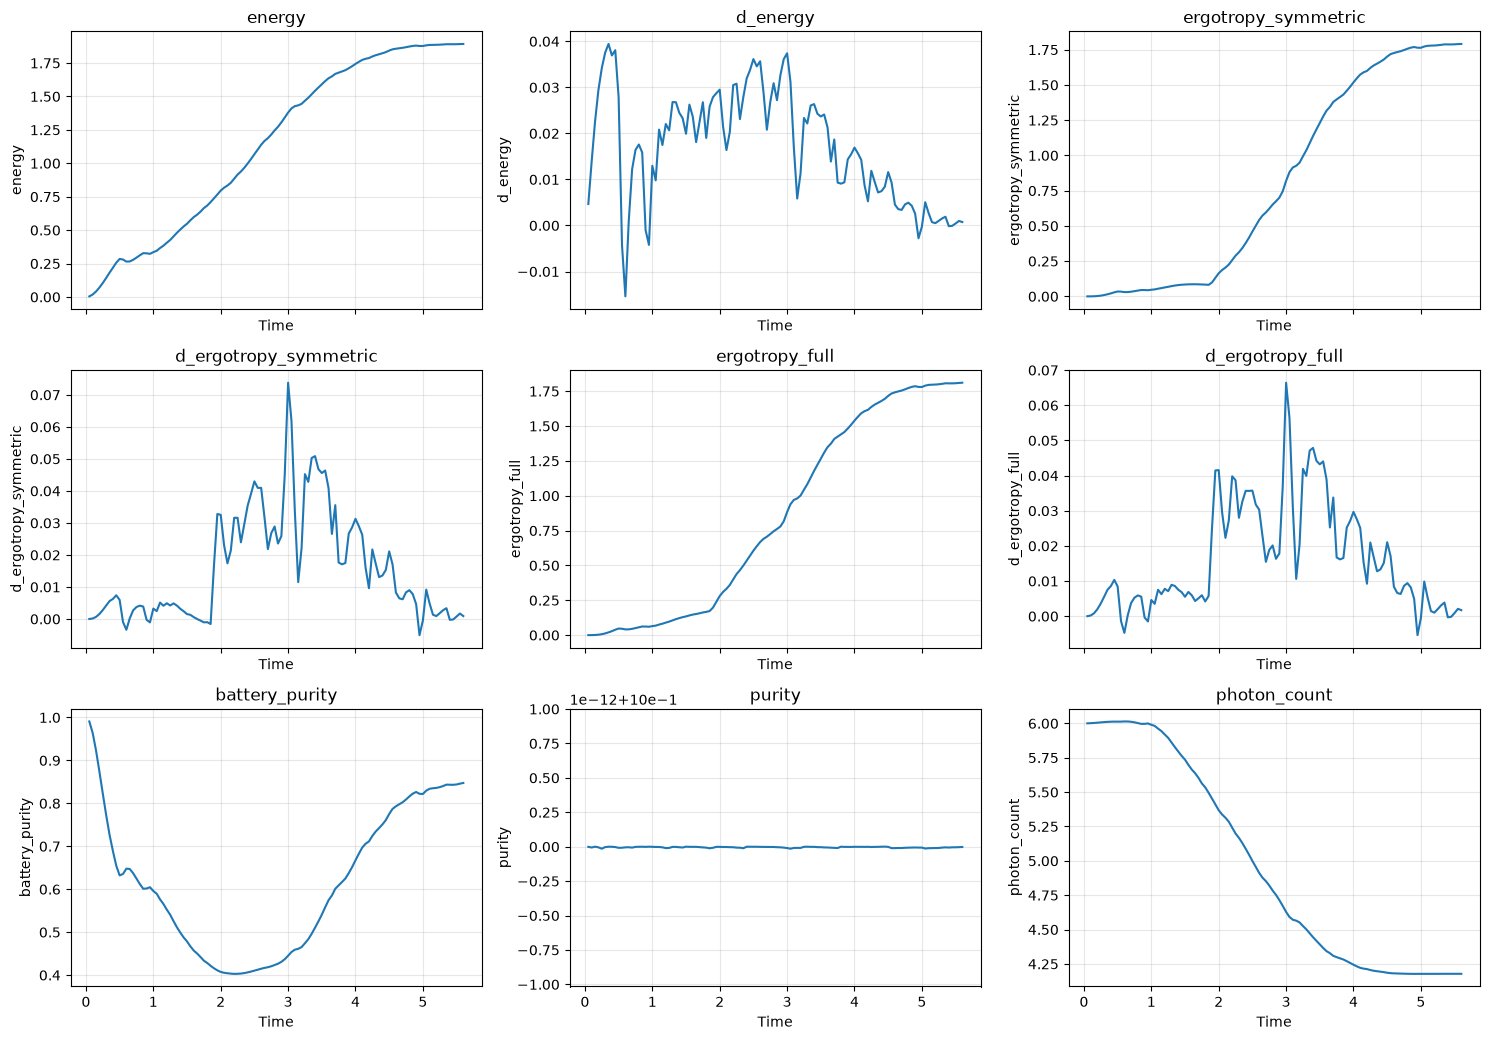

In [6]:
debug.plot_results(history)

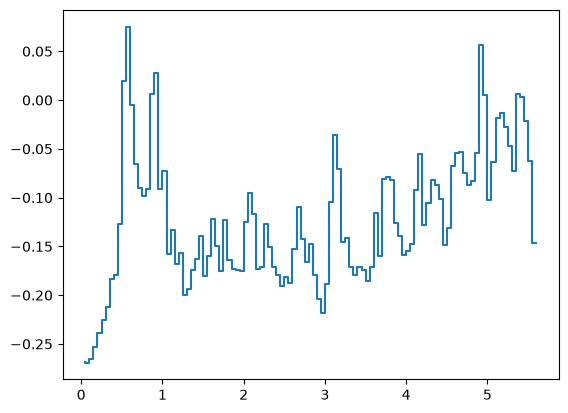

In [9]:
plt.step([h["time"] for h in history], actions)
plt.show()